<a href="https://colab.research.google.com/github/Oyakata32/Lesson17/blob/main/Zaj%C4%99cia_17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

(-10.0, 10.0)

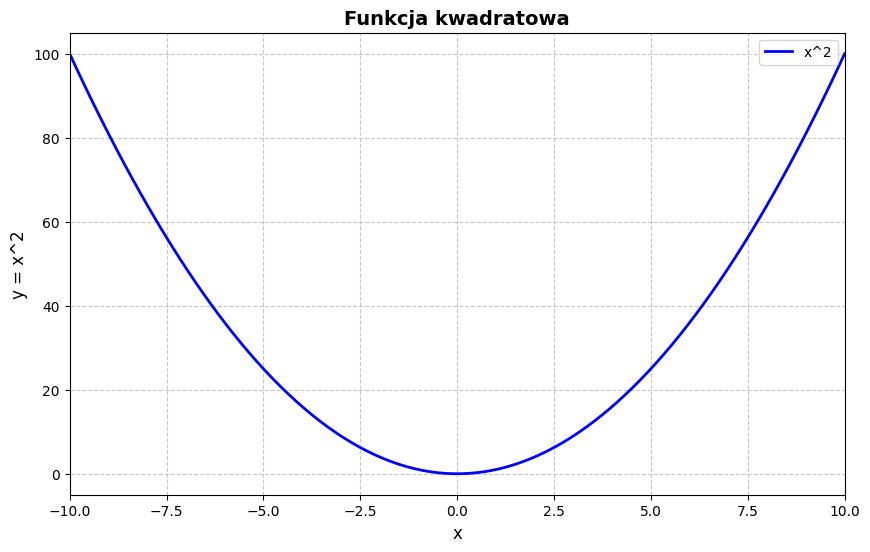

In [7]:
#Zadanie 1 – Podstawowy wykres liniowy
# Import głównego modułu matplotlib
import matplotlib.pyplot as plt
import numpy as np
# Utworzenie figury i osi - preferowana metoda obiektowa
fig, ax = plt.subplots(figsize=(10, 6)) # figsize w calach (szerokość, wysokość)
# Przygotowanie danych
x = np.linspace(-10, 10, 100) # 100 punktów od 0 do 10
y = pow(x,2)# funkcja sinus
# Rysowanie na obiekcie ax (Axes)
ax.plot(x, y,
color='blue', # kolor linii
linewidth=2, # grubość linii
linestyle='-', # styl: '-', '--', ':', '-.'
label='x^2') # etykieta do legendy
# Dodanie tytułu i etykiet osi
ax.set_title('Funkcja kwadratowa', fontsize=14, fontweight='bold')
ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('y = x^2', fontsize=12)
# Dodanie legendy
ax.legend(loc='upper right') # lokalizacja legendy
# Dodanie siatki
ax.grid(True, linestyle='--', alpha=0.7)
# Ustawienie limitów osi
ax.set_xlim(-10, 10)


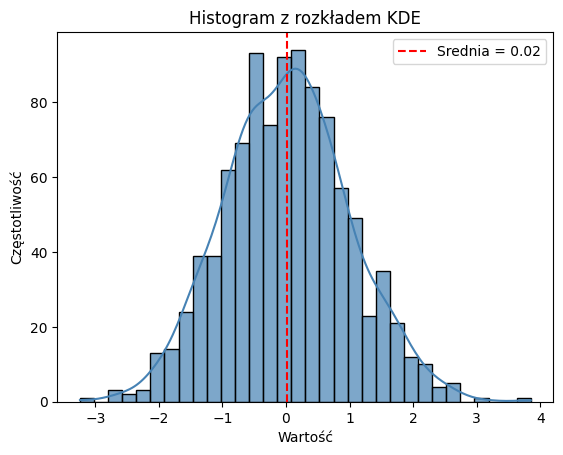

In [11]:
#Zadanie 2 – Histogram z KDE
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

data = np.random.normal(loc=0, scale=1, size=1000)
sns.histplot(
    data,
    bins=32,
    kde=True,
    color='steelblue',
    alpha=0.7
)
mean = np.mean(data)
plt.axvline(
    mean,
    color='red',
    linestyle='--',
    label=f'Srednia = {mean:.2f}'
)

plt.title('Histogram z rozkładem KDE')
plt.xlabel('Wartość')
plt.ylabel('Częstotliwość')
plt.legend()

plt.show()

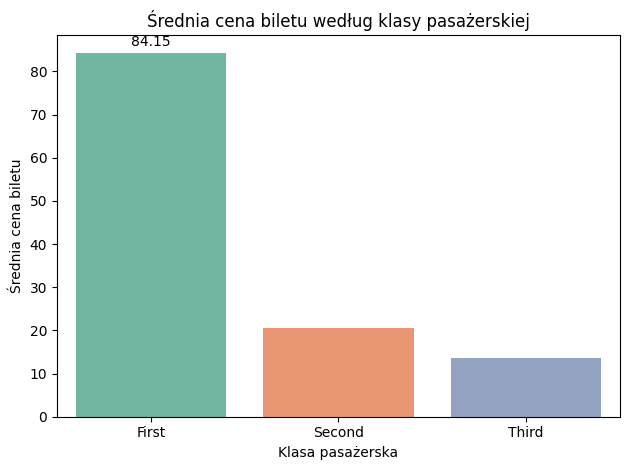

In [17]:
#zadanie 3
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

titanic = sns.load_dataset('titanic')

avg_fare = titanic.groupby('class', observed=True)['fare'].mean()

ax = sns.barplot(
    x=avg_fare.index,
    y=avg_fare.values,
    hue=avg_fare.index,
    palette='Set2',
    legend=False
)

ax.bar_label(ax.containers[0], fmt='%.2f', padding=3)

plt.title('Średnia cena biletu według klasy pasażerskiej')
plt.xlabel('Klasa pasażerska')
plt.ylabel('Średnia cena biletu')
plt.tight_layout()
plt.show()

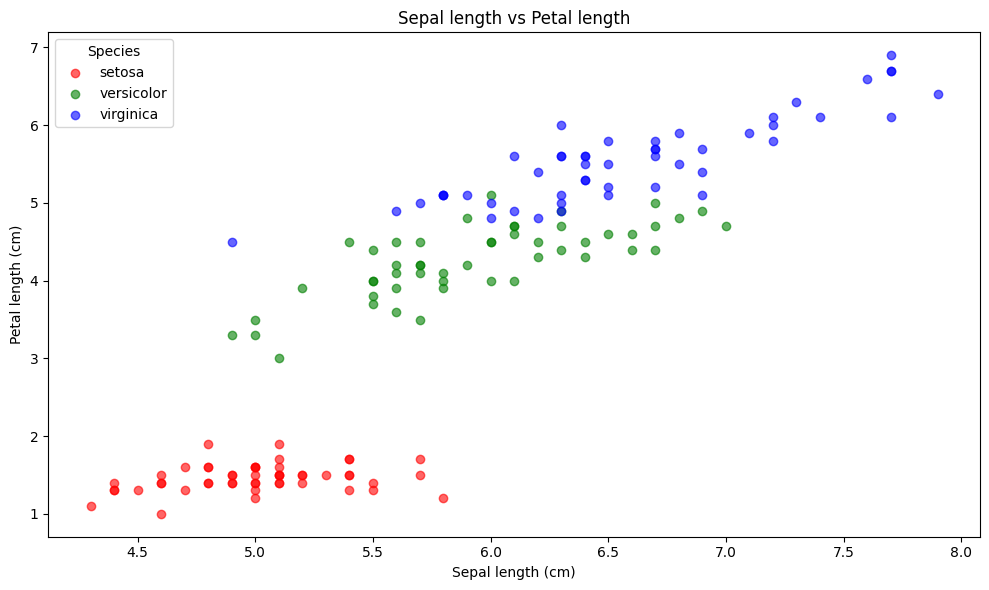

In [29]:
# zadanie 4
"""Na datasecie Iris stwórz scatter plot pokazujący zależność między sepal_length a petal_length, z
kolorowaniem według gatunku.
Dataset: iris = sns.load_dataset('iris')
Wymagania:
Różne kolory dla każdego gatunku
Dodaj legendę
Ustaw przezroczystość 0.6"""


import seaborn as sns
import matplotlib.pyplot as plt

iris = sns.load_dataset('iris')

plt.figure(figsize=(10, 6))

colors = {
    'setosa': 'red',
    'versicolor': 'green',
    'virginica': 'blue'
}

for species in iris['species'].unique():
    subset = iris[iris['species'] == species]

    plt.scatter(
        subset['sepal_length'],
        subset['petal_length'],
        color=colors[species],
        label=species,
        alpha=0.6
    )

plt.title('Sepal length vs Petal length')
plt.xlabel('Sepal length (cm)')
plt.ylabel('Petal length (cm)')
plt.legend(title='Species')

plt.tight_layout()
plt.show()


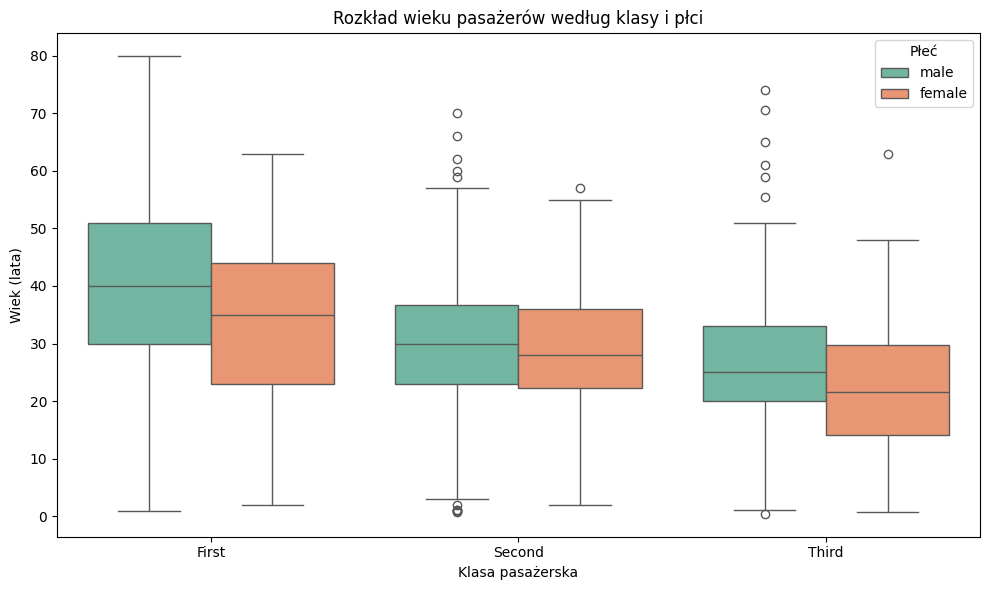

In [39]:
# Zadanie 5 – Box plot porównawczy

import matplotlib.pyplot as plt
import seaborn as sns

titanic = sns.load_dataset('titanic')

fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=titanic,
    x='class',
    y='age',
    hue='sex',
    palette='Set2',
    ax=ax
)

ax.set_title('Rozkład wieku pasażerów według klasy i płci')
ax.set_xlabel('Klasa pasażerska')
ax.set_ylabel('Wiek (lata)')
ax.legend(title='Płeć')

plt.tight_layout()
plt.show()

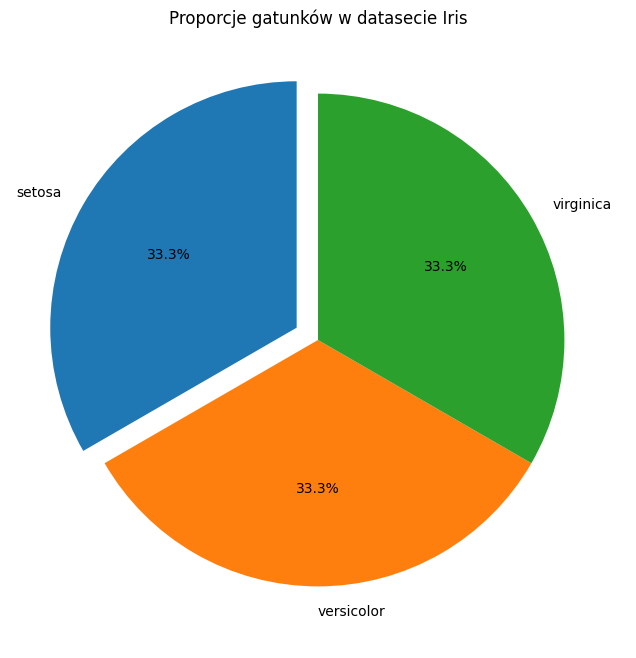

In [53]:
#Zadanie 6 – Pie chart
import seaborn as sns
import matplotlib.pyplot as plt

iris = sns.load_dataset('iris')

species_counts = iris['species'].value_counts()

explode = [0.1 if i == species_counts.argmax() else 0
           for i in range(len(species_counts))]

fig, ax = plt.subplots(figsize=(8, 8))

ax.pie(
    species_counts,
    labels=species_counts.index,
    autopct='%1.1f%%',
    explode=explode,
    startangle=90
)

ax.set_title('Proporcje gatunków w datasecie Iris')
plt.show()

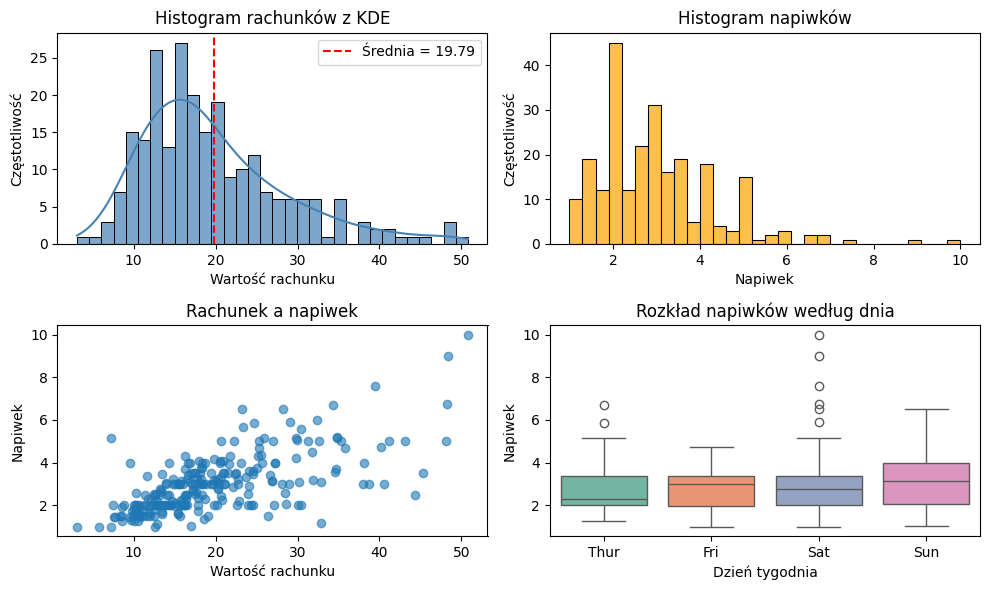

In [81]:
# Zadanie 7 – Subplots 2x2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

tips = sns.load_dataset('tips')
fig, axes = plt.subplots(2, 2, figsize=(10, 6))

# 1. Histogram total_bill
sns.histplot(
    data=tips, x='total_bill', bins=32,
    kde=True, color='steelblue', alpha=0.7,
    ax=axes[0, 0]
)
mean = tips['total_bill'].mean()
axes[0, 0].axvline(
    mean, color='red', linestyle='--',
    label=f'Średnia = {mean:.2f}'
)
axes[0, 0].set_title('Histogram rachunków z KDE')
axes[0, 0].set_xlabel('Wartość rachunku')
axes[0, 0].set_ylabel('Częstotliwość')
axes[0, 0].legend()

# 2. Histogram tip
sns.histplot(
    data=tips, x='tip', bins=30,
    color='orange', alpha=0.7,
    ax=axes[0, 1]
)
axes[0, 1].set_title('Histogram napiwków')
axes[0, 1].set_xlabel('Napiwek')
axes[0, 1].set_ylabel('Częstotliwość')

# 3. Scatter: total_bill vs tip
axes[1, 0].scatter(
    tips['total_bill'], tips['tip'], alpha=0.6
)
axes[1, 0].set_title('Rachunek a napiwek')
axes[1, 0].set_xlabel('Wartość rachunku')
axes[1, 0].set_ylabel('Napiwek')

# 4. Boxplot: tip według dnia
sns.boxplot(
    data=tips, x='day', y='tip',
    hue='day', palette='Set2',
    legend=False, ax=axes[1, 1]
)
axes[1, 1].set_title('Rozkład napiwków według dnia')
axes[1, 1].set_xlabel('Dzień tygodnia')
axes[1, 1].set_ylabel('Napiwek')

plt.tight_layout()
plt.show()

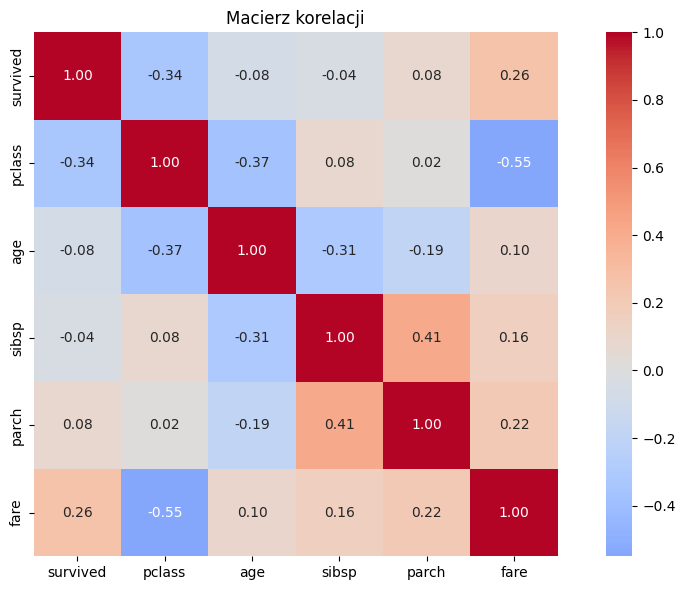

In [84]:
#Zadanie 8 – Heatmap korelacji

import matplotlib.pyplot as plt
import seaborn as sns

titanic = sns.load_dataset('titanic')
fig, ax = plt.subplots(figsize=(10, 6))

numeric_cols = titanic.select_dtypes(include=['number']).columns
correlation = titanic[numeric_cols].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    square=True,
    ax=ax
)

ax.set_title('Macierz korelacji')
plt.tight_layout()
plt.show()

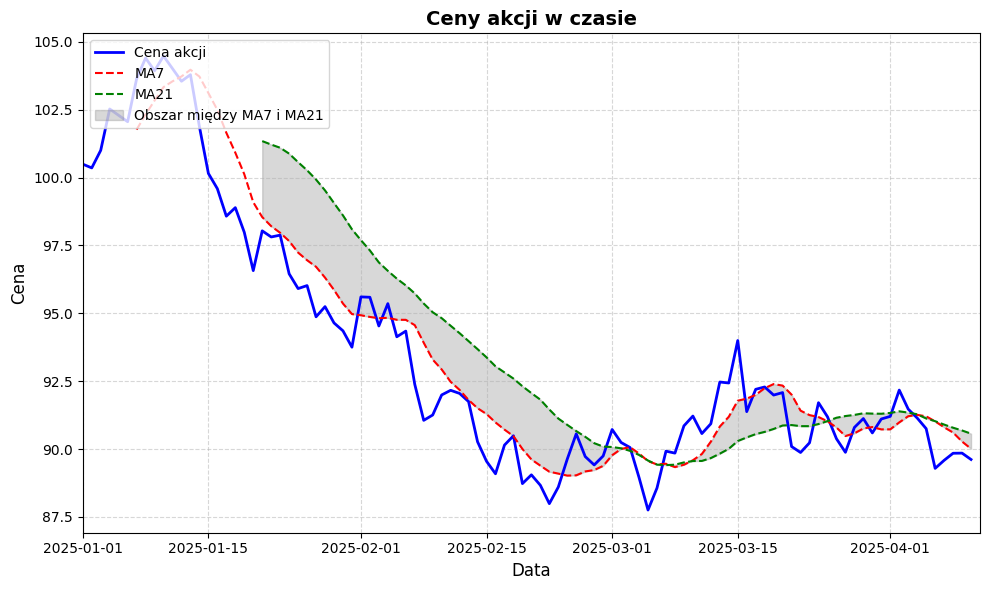

In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

dates = pd.date_range('2025-01-01', periods=100)
price = 100 + np.cumsum(np.random.randn(100))

df = pd.DataFrame({'date': dates, 'price': price})

# Obliczanie średnich kroczących
df['MA7'] = df['price'].rolling(window=7).mean()
df['MA21'] = df['price'].rolling(window=21).mean()

fig, ax = plt.subplots(figsize=(10, 6))

# Główna linia ceny
ax.plot(
    df['date'], df['price'],
    color='blue',
    linewidth=2,
    label='Cena akcji'
)

# Średnia krocząca 7-dniowa
ax.plot(
    df['date'], df['MA7'],
    color='red',
    linestyle='--',
    label='MA7'
)

# Średnia krocząca 21-dniowa
ax.plot(
    df['date'], df['MA21'],
    color='green',
    linestyle='--',
    label='MA21'
)

# Zacieniony obszar między średnimi
ax.fill_between(
    df['date'],
    df['MA7'],
    df['MA21'],
    color='gray',
    alpha=0.3,
    label='Obszar między MA7 i MA21'
)

ax.set_title('Ceny akcji w czasie', fontsize=14, fontweight='bold')
ax.set_xlabel('Data', fontsize=12)
ax.set_ylabel('Cena', fontsize=12)

ax.legend(loc='upper left')
ax.grid(True, linestyle='--', alpha=0.5)

ax.set_xlim(
    pd.Timestamp('2025-01-01'),
    pd.Timestamp('2025-01-01') + pd.Timedelta(days=100)
)

plt.tight_layout()
plt.show()

In [102]:
#zadanie 15
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# =====================================
# 1. GENEROWANIE SYMULOWANYCH DANYCH OHLCV
# =====================================

np.random.seed(42)

n = 250
dates = pd.bdate_range(start='2025-01-01', periods=n)

# Symulacja cen
initial_price = 100
daily_returns = np.random.normal(loc=0.0005, scale=0.02, size=n)

close = initial_price * np.cumprod(1 + daily_returns)

# Cena otwarcia: poprzednie zamknięcie + luka cenowa
open_price = np.empty(n)
open_price[0] = initial_price

open_price[1:] = close[:-1] * (
    1 + np.random.normal(0, 0.005, n - 1)
)

# Maksimum i minimum dnia
intraday_range = np.random.uniform(0.003, 0.025, n)

high = np.maximum(open_price, close) * (1 + intraday_range)
low = np.minimum(open_price, close) * (1 - intraday_range)

# Symulacja wolumenu
volume = np.random.randint(100_000, 1_500_000, n)

df = pd.DataFrame({
    'Date': dates,
    'Open': open_price,
    'High': high,
    'Low': low,
    'Close': close,
    'Volume': volume
})

# =====================================
# 2. OBLICZANIE RSI (14)
# =====================================

change = df['Close'].diff()

gain = change.clip(lower=0)
loss = -change.clip(upper=0)

# Wygładzanie Wildera
avg_gain = gain.ewm(
    alpha=1/14, min_periods=14, adjust=False
).mean()

avg_loss = loss.ewm(
    alpha=1/14, min_periods=14, adjust=False
).mean()

rs = avg_gain / avg_loss

df['RSI'] = 100 - (100 / (1 + rs))

# Obsługa szczególnych przypadków
df.loc[(avg_loss == 0) & (avg_gain > 0), 'RSI'] = 100
df.loc[(avg_loss == 0) & (avg_gain == 0), 'RSI'] = 50

# Dzienne stopy zwrotu w procentach
df['Returns'] = df['Close'].pct_change() * 100

# Kolory wolumenu: zielony przy wzroście, czerwony przy spadku
volume_colors = np.where(
    df['Close'] >= df['Open'],
    'rgba(38, 166, 91, 0.65)',
    'rgba(239, 83, 80, 0.65)'
)

# =====================================
# 3. UKŁAD DASHBOARDU
# =====================================

fig = make_subplots(
    rows=4,
    cols=1,
    shared_xaxes=False,
    vertical_spacing=0.06,
    row_heights=[0.42, 0.18, 0.22, 0.18],
    subplot_titles=(
        'Cena akcji — Candlestick',
        'Wolumen obrotu',
        'RSI (14)',
        'Rozkład dziennych stóp zwrotu'
    )
)

# =====================================
# WYKRES 1: CANDLESTICK
# =====================================

fig.add_trace(
    go.Candlestick(
        x=df['Date'],
        open=df['Open'],
        high=df['High'],
        low=df['Low'],
        close=df['Close'],
        name='Cena OHLC',
        increasing_line_color='#26a69a',
        decreasing_line_color='#ef5350'
    ),
    row=1, col=1
)

# =====================================
# WYKRES 2: VOLUME
# =====================================

fig.add_trace(
    go.Bar(
        x=df['Date'],
        y=df['Volume'],
        name='Wolumen',
        marker_color=volume_colors,
        hovertemplate=(
            'Data: %{x|%Y-%m-%d}<br>'
            'Wolumen: %{y:,.0f}<extra></extra>'
        )
    ),
    row=2, col=1
)

# =====================================
# WYKRES 3: RSI
# =====================================

fig.add_trace(
    go.Scatter(
        x=df['Date'],
        y=df['RSI'],
        mode='lines',
        name='RSI (14)',
        line=dict(color='#7e57c2', width=2),
        hovertemplate=(
            'Data: %{x|%Y-%m-%d}<br>'
            'RSI: %{y:.2f}<extra></extra>'
        )
    ),
    row=3, col=1
)

# Poziomy RSI: 30 i 70
fig.add_hline(
    y=70, line_dash='dash',
    line_color='red', row=3, col=1
)

fig.add_hline(
    y=30, line_dash='dash',
    line_color='green', row=3, col=1
)

fig.add_hline(
    y=50, line_dash='dot',
    line_color='gray', row=3, col=1
)

# =====================================
# WYKRES 4: HISTOGRAM STÓP ZWROTU
# =====================================

fig.add_trace(
    go.Histogram(
        x=df['Returns'].dropna(),
        nbinsx=35,
        name='Dzienne stopy zwrotu',
        marker_color='steelblue',
        opacity=0.8,
        hovertemplate=(
            'Stopa zwrotu: %{x:.2f}%<br>'
            'Liczba obserwacji: %{y}<extra></extra>'
        )
    ),
    row=4, col=1
)

# =====================================
# 4. FORMATOWANIE DASHBOARDU
# =====================================

fig.update_layout(
    title=dict(
        text='INTERAKTYWNY DASHBOARD ANALIZY AKCJI',
        x=0.5,
        xanchor='center'
    ),
    height=1200,
    template='plotly_white',
    hovermode='x',
    showlegend=True,
    legend=dict(
        orientation='h',
        yanchor='bottom',
        y=1.01,
        xanchor='right',
        x=1
    ),
    margin=dict(l=70, r=35, t=110, b=60)
)

# Opisy osi
fig.update_yaxes(title_text='Cena', row=1, col=1)
fig.update_yaxes(title_text='Wolumen', row=2, col=1)
fig.update_yaxes(title_text='RSI', range=[0, 100], row=3, col=1)
fig.update_yaxes(title_text='Liczba dni', row=4, col=1)
fig.update_xaxes(title_text='Data', row=3, col=1)
fig.update_xaxes(title_text='Stopa zwrotu (%)', row=4, col=1)

# Ukryj rangeslider pod wykresem świecowym
fig.update_xaxes(rangeslider_visible=False, row=1, col=1)

# Wyświetlenie
fig.show()
